# GR tensor modes: a Gaussian state defined in the L/R basis

**Based on the uploaded `GR(5).ipynb`.** This notebook adopts a NEW L/R
initial-state ansatz. It is **not** the passive circular-basis representation
of the original linear-polarization state.

For one independent Fourier pair (no double counting of $\boldsymbol k$ and
$-\boldsymbol k$), use
$$
\Psi_k=N_k\exp[-\boldsymbol h_{\boldsymbol k}^{\dagger}
 B_k\boldsymbol h_{\boldsymbol k}],\qquad
\boldsymbol h_{\boldsymbol k}=(h_{L,\boldsymbol k},h_{R,\boldsymbol k})^T,
$$
$$
B_k=b_{0k}I+b_{1k}\sigma_1+b_{2k}\sigma_2+b_{3k}\sigma_3,
\qquad b_{3k}(\tau_i)=0.
$$
The standard Pauli convention gives
$$
B_k=\begin{pmatrix}b_{0k}+b_{3k}&b_{1k}-i b_{2k}\\
b_{1k}+i b_{2k}&b_{0k}-b_{3k}\end{pmatrix}.
$$
**$b_2=0$ is a restriction on the state, not a consequence of GR.** It is
preserved by the quadratic GR evolution used here. All $b_j$ can be complex;
$b_{jR}$ below means $\operatorname{Re}b_j$, not the right helicity.

Preserved from the source: $\beta_T^2=a^2M_{\rm Pl}^2/2$, the full
$H_{3/2}^{(2)}$ auxiliary initial mode, its phase, the nonlinear mode equation,
$H= M_{\rm Pl}=1$, $1\leq k\leq30$, 500 modes, tolerances, and cases
$(\widetilde b_1,\widetilde b_3)=(0,0),(0.45,0),(0.30,0.30)$.
There is no replacement by WKB and no additional rephasing of $g_k(\tau_i)$.

The horizontal axis for spectral plots is $x_i=-k\tau_i$. Font sizes are
30 pt (axis labels), 14 pt (ticks), and 22 pt (legend), as requested earlier.
Outputs go to **`GR_LR_BD_outputs/`**, leaving the original outputs intact.
The variable `P_total` retains the original definition $P_{LL}+P_{RR}$;
no extra tensor-contraction factor has been introduced.

Run the cells in order. Dependencies: NumPy, SciPy and Matplotlib.


In [74]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.special import hankel1, h1vp, hankel2, h2vp
from pathlib import Path
import json


# Plot settings matched to WKB_Parity_Poster(2).ipynb.
STYLE = {
    "figure_size": (9, 6),
    "font_family": "DejaVu Sans",
    "font_size": 14,
    "title_size": 20,
    "axis_label_size": 30,
    "tick_label_size": 14,
    "legend_size": 22,
}
plt.rcParams.update({
    "font.family": STYLE["font_family"],
    "font.size": STYLE["font_size"],
    "mathtext.fontset": "stix",
    "axes.unicode_minus": False,
    "axes.labelsize": STYLE["axis_label_size"],
    "axes.titlesize": STYLE["title_size"],
    "xtick.labelsize": STYLE["tick_label_size"],
    "ytick.labelsize": STYLE["tick_label_size"],
    "legend.fontsize": STYLE["legend_size"],
    "figure.figsize": STYLE["figure_size"],
})


## Evolution and observables (same scalar equations, new subsystem labels)

In the original physical-$h$ normalization,
$$
iB_k'=\beta_T^{-2}B_k^2-\beta_T^2k^2I,
\qquad ib_{jk}'=2b_{0k}b_{jk}/\beta_T^2\quad(j=1,2,3).
$$
Thus $b_2(\tau_i)=0$ implies $b_2(\tau)=0$. In this restricted family,
$$
b_0=-i\beta_T^2\left(\frac{g'}g-\frac{\beta_T'}{\beta_T}\right),\quad
b_j=\frac{\beta_T^2}{g^2}\widetilde b_j\quad(j=1,2,3),\quad
 g''+\left(k^2-\frac2{\tau^2}\right)g
 =\frac{\widetilde b_1^2+\widetilde b_3^2}{g^3}.
$$
The source is the sum of **complex squares**, not squared magnitudes.
The code computes $b_{0R}$ from $g'/g$ rather than assuming a conserved
auxiliary Wronskian when mixing is nonzero.

With $M=(B+B^\dagger)/2$ and $D=\det M$,
$$
\langle\boldsymbol h\boldsymbol h^\dagger\rangle=\tfrac12M^{-1},\quad
D=b_{0R}^2-b_{1R}^2-b_{3R}^2>0,\quad b_{0R}>0,
$$
$$
P_{LL}=\frac{k^3}{4\pi^2}\frac{b_{0R}-b_{3R}}{D},\quad
P_{RR}=\frac{k^3}{4\pi^2}\frac{b_{0R}+b_{3R}}{D},\quad
P_{LR}=-\frac{k^3}{4\pi^2}\frac{b_{1R}}{D},\quad
\Pi=\frac{P_{LL}-P_{RR}}{P_{LL}+P_{RR}}=-\frac{b_{3R}}{b_{0R}}.
$$
Here $P_{LR}$ is real because $b_2=0$. A complex $b_1$ is still allowed.
A nonzero $b_1$ makes this pure Gaussian nonfactorizable across L/R;
$b_3$ alone changes diagonal widths and does not entangle L with R.
Nonzero $\Pi$ in this GR calculation originates in the chosen initial state,
not a parity-violating GR Hamiltonian. Nonzero L/R cross-correlations also
require care when interpreting statistical isotropy; isotropy is not
established by the isotropic background alone.

### Case A: $\widetilde b_1=\widetilde b_2=0$


In [ ]:
# ============================================================
# 1. User parameters
# ============================================================

H = 1.0
MPL = 1.0

# Dimensionless wavenumber range.
# tau0 is chosen as in the paper: k_min exits the horizon at tau0.
K_MIN = 1.0
K_MAX = 30.0
N_K = 1200

# Largest k satisfies -k*tau_f = SUPERHORIZON_X at the final time.
SUPERHORIZON_X = 1.0e-3

# LR state parameters: b1 is cross-kernel mixing; b3 is diagonal imbalance.
# 
BTILDE1_AMP = 0.00
BTILDE1_PHASE = 0.0

BTILDE2_AMP = 0.00
BTILDE2_PHASE = 0.0

# Numerical accuracy
RTOL = 1.0e-9
ATOL = 1.0e-11

# Number of time samples saved for one representative mode
N_TIME = 1000

# Output
OUTPUT_DIR = Path("GR_LR_BD_outputs")/ "case_A"
CSV_NAME = "GR_LR_power_spectra.csv"
# ============================================================
# 2. Background
# ============================================================

def a_of_tau(tau):
    """Exact de Sitter scale factor."""
    return -1.0 / (H * tau)


def beta2_of_tau(tau):
    """beta^2 = a^2 M_pl^2/2, as in the paper."""
    return (a_of_tau(tau) * MPL) ** 2/2


def beta_pp_over_beta(tau):
    """For exact de Sitter: beta''/beta = a''/a = 2/tau^2."""
    return 2.0 / tau**2


# ============================================================
# 3. Bunch-Davies initial mode g_k
# ============================================================

NU_GAMMA = 1.5


def u_bd(tau, k):
    """
    Physical positive-frequency BD mode.

    u_BD ~ exp(-ik tau)
    W[u_BD, u_BD*] = +i

    「「「Used only for the standard BD reference power.」」」
    """
    x = -k * tau
    pref = 0.5 * np.sqrt(-np.pi * tau)
    return pref * hankel1(NU_GAMMA, x)


def u_bd_prime(tau, k):
    """Conformal-time derivative of g_bd."""
    x = -k * tau
    pref = 0.5 * np.sqrt(-np.pi * tau)

    # d/dtau [sqrt(-pi tau)/2] = pref/(2 tau)
    pref_prime = pref / (2.0 * tau)

    # d/dtau H_nu(-k tau) = -k H_nu'(x)
    return (
        pref_prime * hankel1(NU_GAMMA, x)
        - k * pref * h1vp(NU_GAMMA, x, 1)
    )
##returnのところがよくわからない。g_bdの微分を計算しているのはわかるが、h1vpの引数がよくわからない。
##h1vp(NU_GAMMA, x, 1)は、hankel1の微分を計算している。h1vpはscipy.specialの関数で、第一引数が階数、第二引数が引数、第三引数が微分の次数を指定する。ここでは1階微分を計算しているので、第三引数は1になっている。
##g'はg_bdの微分なので、g_bdの定義に従って計算すると、g' = d/dtau [sqrt(-pi tau)/2 * H^(1)_{3/2}(-k tau)]となる。これを積の微分法則で展開すると、pref_prime * hankel1(NU_GAMMA, x) - k * pref * h1vp(NU_GAMMA, x, 1)となる。

def g_aux_bd_exact(tau, k):
    """
    Auxiliary mode entering the Riccati parametrization

        i b0 = beta^2 (g'/g - beta'/beta).

    To represent the normalizable BD Gaussian,
    g_aux = u_BD* ~ H^(2).
    """
    x = -k * tau
    pref = 0.5 * np.sqrt(-np.pi * tau)

    return pref * hankel2(NU_GAMMA, x)


def g_aux_bd_exact_prime(tau, k):
    x = -k * tau
    pref = 0.5 * np.sqrt(-np.pi * tau)
    pref_prime = pref / (2.0 * tau)

    return (
        pref_prime * hankel2(NU_GAMMA, x)
        - k * pref * h2vp(NU_GAMMA, x, 1)
    )

# ============================================================
# 4. Tensor-only evolution equation
# ============================================================

def rhs_real(tau, y, k, btilde1, btilde2):

    g = y[0] + 1j * y[1]
    gp = y[2] + 1j * y[3]

    Xi = btilde1**2 + btilde2**2

    gpp = (
        -(k**2 - 2.0 / tau**2) * g
        + Xi / g**3
    )

    Jp = np.imag(
        np.conj(g) * Xi / g**3
    )

    return np.array([
        gp.real,
        gp.imag,
        gpp.real,
        gpp.imag,
        Jp
    ])
##returnでは、g'とg''の実部と虚部を配列として返している。これにより、solve_ivpが4つの実数方程式として扱えるようになる。

def initial_reference_data(tau0, k):

    g0 = g_aux_bd_exact(tau0, k)
    gp0 = g_aux_bd_exact_prime(tau0, k)

    # Fix the initial phase: g_k(tau_i) > 0
    phase = np.exp(-1j * np.angle(g0))

    g0 = g0 * phase
    gp0 = gp0 * phase

    return g0, gp0

def solve_mode(k, tau0, tauf, btilde1, btilde2, t_eval=None):
    """Numerically evolve one k-mode."""
    "ここでgを単にBD回と同じH3/2(1)と同じにするとJ=-1/2でb0kR<0となり規格化条件満たさなくなる。よってH3/2(2)にする​"
    g0, gp0 = initial_reference_data(tau0, k)

    y0 = np.array([
        g0.real,
        g0.imag,
        gp0.real,
        gp0.imag,
        0.5
        ])

    sol = solve_ivp(
        rhs_real,
        (tau0, tauf),
        y0,
        args=(k, btilde1, btilde2),
        method="DOP853",
        t_eval=t_eval,
        rtol=RTOL,
        atol=ATOL,
    )
    ##solve_ivpは、常微分方程式の初期値問題を数値的に解く関数である。ここでは、rhs_real(g''とg'の虚部実部のarray)を右辺として、tau0からtaufまでの範囲で、
    ##初期条件y0を与えて解を求めている。argsでkとbtilde1を渡している。methodはDOP853という高精度のルンゲクッタ法を使用している。
    ##t_evalは解を評価する時刻の配列であり、rtolとatolは相対誤差と絶対誤差の許容値である。
    if not sol.success:
        raise RuntimeError(
            f"ODE integration failed for k={k}: {sol.message}"
        )

    g = sol.y[0] + 1j * sol.y[1]
    gp = sol.y[2] + 1j * sol.y[3]
    J_arr = sol.y[4]

    return sol.t, g, gp, J_arr
#sol.tは、解が評価された時刻の配列であり、sol.yは、解の各成分の配列である。ここでは、gとg'を複素数として再構成して返している。

# ============================================================
# 5. Gaussian kernel, covariance, and primordial power
# ============================================================

def observables_from_g(k, tau, g, gp, btilde1, btilde2, J):
    """
    Compute the L/R Gaussian kernel and equal-time two-point functions.
    The numerical equations match the source, but this is a NEW LR state.

    We use:
        B_R = [[b0_R+b3_R, b1_R],
               [b1_R, b0_R-b3_R]]

    Paper Eq. (2.19):
        b0 = -1j*beta^2*(gprime/g - beta_prime/beta)
        

    Paper Eq. (2.22):
        b1 = beta^2/g^2 * btilde1

    Paper Eq. (2.23):
        b3 = beta^2/g^2 * btilde2

    Gaussian covariance:
        <h h^dagger> = 1/2 * M^{-1}, M=(B+B^dagger)/2.
        For b2=0, M equals the entrywise real part of B.
    """
    "beta^2"
    beta2 = beta2_of_tau(tau)

    "beta_p_over_beta=beta'/beta"
    beta_p_over_beta = -1.0 / tau

    # --------------------------------------------------------
    # Riccati auxiliary mode
    #
    # i b0 = beta^2 (g'/g - beta'/beta)
    # --------------------------------------------------------
    ratio = gp / g

    b0 = -1j * beta2 * (
        ratio - beta_p_over_beta
    )

    b0_R = beta2 * J / np.abs(g)**2

    # Equivalent and numerically more transparent:
    # b0_R = beta^2 Im(g'/g)

    # --------------------------------------------------------
    # Tensor mixing kernels
    # --------------------------------------------------------
    b1 = beta2 * btilde1 / g**2
    b2 = beta2 * btilde2 / g**2
    b3 = 0.0j  # Initial-state restriction preserved in GR.
    
    b1_R = np.real(b1)
    b2_R = np.real(b2)
    b3_R = np.real(b3)


    det_M = b0_R**2 - (b2_R**2 + b1_R**2)
    eig_small = b0_R -(b2_R**2 + b1_R**2)**0.5
    eig_large = b0_R +(b2_R**2 + b1_R**2)**0.5

    #固有値が正になってるかチェック
    if np.any(eig_small <= 0.0):
        raise ValueError(
        f"Normalizability lost at k={k}: "
        f"lambda_min = {eig_small}"
    )



    hh_LL = (b0_R - b3_R) / (2.0 * det_M)
    hh_RR = (b0_R + b3_R) / (2.0 * det_M)
    hh_LR = -(b1_R-1j * b2_R)  / (2.0 * det_M)
    hh_RL = -(b1_R+1j * b2_R)  / (2.0 * det_M)

    pref = k**3 / (2.0 * np.pi**2)

    P_LL = pref * hh_LL
    P_RR = pref * hh_RR
    P_LR = pref * hh_LR
    P_RL = pref * hh_RL

    # Dimensionless cross-correlation coefficient.
    rho_LR = hh_LR / np.sqrt(hh_LL * hh_RR)
    #rho_LRは、hh_LRをhh_LLとhh_RRの幾何平均で割ったもので、LとRの相関係数を表す。L と R の field amplitude がどの程度 cross-correlate しているか。
    # rho_LR = 0 の場合、L と R は uncorrelated であり、rho_LR = ±1 の場合、完全に correlated である。
    return {
        "b0": b0, "b1": b1, "b2": b2, "b3": b3,
        "Pi": -b3_R / b0_R,
        "b0_R": b0_R,
        "b1_R": b1_R,
        "b3_R": b3_R,
        "J":J,
        "det_M": det_M,
        "eig_small": eig_small,
        "eig_large": eig_large,
        "hh_LL": hh_LL,
        "hh_RR": hh_RR,
        "hh_LR": hh_LR,
        "P_LL": P_LL,
        "P_RR": P_RR,
        "P_LR": P_LR,
        "P_RL": P_RL,
        "rho_LR": rho_LR,
    }


def P_bd_per_polarization(k, tau):
    """
    Zero-entanglement reference in exactly the same paper convention.
    For btilde1=btilde2=0:
        <h_sigma h_sigma> = |g_BD|^2 / beta^2.
    """
    u = u_bd(tau, k)
    hh = np.abs(u)**2 / beta2_of_tau(tau)
    return k**3 / (2.0 * np.pi**2) * hh

#entanglement なしの標準 BD 結果を計算。そしてNon-BD結果と比較する。


# ============================================================
# 6. Main scan over k
# ============================================================

def main():
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    k_array = np.geomspace(K_MIN, K_MAX, N_K)
    #K_MINからK_MAXまでの範囲で、N_K個のkを対数等間隔で生成する。

    # Paper choice: the longest observable mode exits at tau0.
    tau0 = -1.0 / K_MIN
    x_initial = -tau0 * k_array

    # At tauf, even the shortest wavelength mode is well outside the horizon.
    tauf = -SUPERHORIZON_X / K_MAX

    btilde1 = BTILDE1_AMP * np.exp(1j * BTILDE1_PHASE)
    btilde2 = BTILDE2_AMP * np.exp(1j * BTILDE2_PHASE)

    P_LL = np.empty_like(k_array)
    P_RR = np.empty_like(k_array)
    P_LR = np.empty_like(k_array, dtype=complex)
    P_RL = np.empty_like(k_array, dtype=complex)
    rho_LR = np.empty_like(k_array, dtype=complex)

    Pi = np.empty_like(k_array)
    P_total = np.empty_like(k_array)
    P_total_bd = np.empty_like(k_array)
    P_total_ratio = np.empty_like(k_array)
    P_bd = np.empty_like(k_array)
    min_eig = np.empty_like(k_array)
    J_final = np.empty_like(k_array)

    print("Running tensor (L, R) entanglement (new LR state, b2=0) calculation")
    print(f"tau0 = {tau0:.6e}")
    print(f"tauf = {tauf:.6e}")
    print(f"btilde1 = {btilde1}")
    print(f"btilde2 = {btilde2}")
    print()

    for i, k in enumerate(k_array):

        # --------------------------------------------
        # Check normalizability at the initial time
        # --------------------------------------------

        g0, gp0 = initial_reference_data(tau0, k)

        obs0 = observables_from_g(
            k,
            tau0,
            g0,
            gp0,
            btilde1,
            btilde2,
            J=0.5,
        )

        # --------------------------------------------
        # Evolve from tau0 to tauf
        # --------------------------------------------
        _, g_arr, gp_arr, J_arr = solve_mode(
            k,
            tau0,
            tauf,
            btilde1,
            btilde2,
            t_eval=np.array([tauf]),
        )

        g_f = g_arr[-1]
        gp_f = gp_arr[-1]
        J_f = J_arr[-1]

        # Evaluate observables at the final time
        obs = observables_from_g(
            k,
            tauf,
            g_f,
            gp_f,
            btilde1,
            btilde2,
            J=J_f,
        )

        P_LL[i] = obs["P_LL"]
        P_RR[i] = obs["P_RR"]
        P_LR[i] = obs["P_LR"]
        P_RL[i] = obs["P_RL"]
        Pi[i] = obs["Pi"]
        P_total[i] = P_LL[i] + P_RR[i]
        # Standard BD tensor power:
        # P_bd is one-polarization power, so total BD = 2 * P_bd
        P_bd[i] = P_bd_per_polarization(k, tauf)
        P_total_bd[i] = 2.0 * P_bd[i]
        # Modification of total tensor power relative to BD
        P_total_ratio[i] = P_total[i] / P_total_bd[i]
        rho_LR[i] = obs["rho_LR"]
        min_eig[i] = obs["eig_small"]
        J_final[i] = obs["J"]
        P_bd[i] = P_bd_per_polarization(k, tauf)

    results = {
        "basis": "LR", "state_definition": "new_LR_ansatz_b2_zero",
        "k": k_array, "tau_i": float(tau0), "tau_f": float(tauf),
        "x_initial": x_initial,
        "btilde1": btilde1, "btilde2": btilde2,
        "P_total": P_total, "P_total_bd": P_total_bd,
        "P_total_ratio": P_total_ratio,
        "P_LL": P_LL, "P_RR": P_RR, "P_LR": P_LR, "P_RL": P_RL,
        "P_bd": P_bd, "Pi": Pi, "rho_LR": rho_LR,
        "min_eigenvalue_M": min_eig, "J": J_final,
    }
    # Record the actual run settings alongside the spectra.
    settings = {
        "basis": "LR", "state_definition": "new_LR_ansatz_b2_zero",
        "b2_fixed_to_zero": True,
        "H": H, "MPL": MPL, "beta_T_squared": "a^2*MPL^2/2",
        "K_MIN": K_MIN, "K_MAX": K_MAX, "N_K": N_K,
        "tau_i": float(tau0), "tau_f": float(tauf),
        "btilde1": [float(btilde1.real), float(btilde1.imag)],
        "btilde2": [float(btilde2.real), float(btilde2.imag)],
        "initial_mode": "full Hankel H^(2), original phase retained",
        "RTOL": RTOL, "ATOL": ATOL,
        "P_total_definition": "P_LL + P_RR (same sum as original notebook)",
    }
    (OUTPUT_DIR / "run_settings.json").write_text(
        json.dumps(settings, indent=2), encoding="utf-8"
    )

    # --------------------------------------------------------
    # Save final primordial spectra
    # --------------------------------------------------------
    out = np.column_stack(
        [
            k_array,
            x_initial,
            np.full_like(k_array, tau0),
            P_LL,
            P_RR,
            P_LR,
            P_RL,
            P_total,
            P_bd,
            P_total_bd,
            P_LL / P_bd,
            P_RR / P_bd,
            P_total_ratio,
            rho_LR,
            min_eig,
            J_final,
            Pi,
        ]
    )

    header = (
    "k,"
    "x_initial,"
    "tau_i,"
    "P_LL,"
    "P_RR,"
    "P_LR,"
    "P_RL,"
    "P_total,"
    "P_BD_per_pol,"
    "P_total_BD,"
    "P_LL_over_P_BD,"
    "P_RR_over_P_BD,"
    "P_total_over_P_total_BD,"
    "rho_LR,"
    "min_eigenvalue_M,"
    "J,"
    "Pi_LL_minus_RR"
    )

    np.savetxt(
        OUTPUT_DIR / CSV_NAME,
        out,
        delimiter=",",
        header=header,
        comments="",
    )

    # --------------------------------------------------------
    # Plot 1: primordial powers
    # --------------------------------------------------------
    plt.figure(figsize=STYLE["figure_size"])
    plt.semilogx(x_initial, P_LL, label=r"$P_{LL}$")
    plt.semilogx(x_initial, P_RR, "--", label=r"$P_{RR}$")
    plt.semilogx(x_initial, P_LR, label=r"$P_{LR}$")
    plt.semilogx(x_initial, P_bd, ":", label="BD per helicity")
    plt.xlabel(r"$x=-k\tau_i$", labelpad=11)
    plt.ylabel(r"Primordial power $\mathcal{P}$", labelpad=9)
    plt.legend(loc="upper left" if OUTPUT_DIR.name == "case_B" or OUTPUT_DIR.name == "case_C" else "best", fontsize=18)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR /"tensor_power_spectra.png", dpi=200)
    plt.show()
    plt.close()

    # --------------------------------------------------------
    # Plot 2: change relative to BD
    # --------------------------------------------------------
    plt.figure(figsize=STYLE["figure_size"])
    plt.semilogx(
    x_initial,
    P_LL / P_bd,
    label=r"$P_{LL}/P_{\rm BD}$")
    plt.semilogx(
    x_initial,
    P_RR / P_bd,
    "--",
    label=r"$P_{RR}/P_{\rm BD}$")
    plt.legend()
    plt.axhline(
    1.0,
    linestyle=":",
    linewidth=1.0,
    label=r"BD",
    )
    plt.xlabel(r"$x=-k\tau_i$", labelpad=11)
    plt.ylabel("power / BD power")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "tensor_power_ratio.png", dpi=200)
    plt.close()

    # --------------------------------------------------------
    # Plot 2b: total tensor power relative to BD
    # --------------------------------------------------------
    plt.figure(figsize=STYLE["figure_size"])

    plt.semilogx(
    x_initial,
    P_total_ratio,
    label=r"$P_T/P_T^{\rm BD}$"
    )

    plt.axhline(
    1.0,
    linewidth=1.0,
    label="BD"
    )
    plt.xlabel(r"$x=-k\tau_i$", labelpad=11)
    plt.ylabel(r"$P_T/P_T^{\rm BD}$")
    plt.legend()
    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / "tensor_total_power_ratio.png",
        dpi=200)
    plt.close()

    # --------------------------------------------------------
    # Plot 3: cross-correlation coefficient
    # --------------------------------------------------------
    plt.figure(figsize=STYLE["figure_size"])
    plt.semilogx(x_initial, rho_LR)
    plt.axhline(0.0, linewidth=1.0)
    plt.xlabel(r"$x=-k\tau_i$", labelpad=11)
    plt.ylabel(r"$\rho_{LR}$")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "tensor_cross_correlation.png", dpi=200)
    plt.close()

    # --------------------------------------------------------
    # Plot 4: Wronskian-like quantity J
    # --------------------------------------------------------
    plt.figure(figsize=STYLE["figure_size"])

    plt.semilogx(
        x_initial,
        J_final,
        label=r"$J=g_R g_I'-g_I g_R'$"
    )

    plt.axhline(
        0.5,
        linestyle=":",
        linewidth=1.0,
        label=r"$J=1/2$"
    )

    plt.xlabel(r"$x=-k\tau_i$", labelpad=11)
    plt.ylabel(r"$J$")
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "tensor_J_final.png",
        dpi=200
    )

    plt.close()

    # Chirality diagnostic: GR dynamics do not force a parity-symmetric state.
    plt.figure(figsize=STYLE["figure_size"])
    plt.semilogx(x_initial, Pi, label=r"$\Pi=(P_{LL}-P_{RR})/(P_{LL}+P_{RR})$")
    plt.axhline(0.0, linestyle=":", linewidth=1.0)
    plt.xlabel(r"$x=-k\tau_i$", labelpad=11)
    plt.ylabel(r"$\Pi$", labelpad=9)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "tensor_chirality.png", dpi=200)
    plt.close()

    # --------------------------------------------------------
    # Time evolution for one representative mode
    # --------------------------------------------------------
    k_pivot = np.sqrt(K_MIN * K_MAX)

    # Logarithmically spaced |tau|, converted back to increasing tau.
    abs_tau = np.geomspace(-tau0, -tauf, N_TIME)
    tau_eval = -abs_tau

    tau_arr, g_arr, gp_arr, J_arr = solve_mode(
        k_pivot,
        tau0,
        tauf,
        btilde1,
        btilde2,
        t_eval=tau_eval,
    )

    PL_time = np.empty_like(tau_arr)
    PLR_time = np.empty_like(tau_arr, dtype=complex)
    rho_time = np.empty_like(tau_arr, dtype=complex)
    eig_time = np.empty_like(tau_arr)
    J_time = np.empty_like(tau_arr)

    for j, (tau, g, gp, J) in enumerate(
        zip(tau_arr, g_arr, gp_arr, J_arr)
    ):
        obs = observables_from_g(
            k_pivot,
            tau,
            g,
            gp,
            btilde1,
            btilde2,
            J=J,
        )

        PL_time[j] = obs["P_LL"]
        PLR_time[j] = obs["P_LR"]
        rho_time[j] = obs["rho_LR"]
        eig_time[j] = obs["eig_small"]
        J_time[j] = obs["J"]
    # --------------------------------------------------------
    # Wronskian directly calculated from g and g'
    #
    # W(g_k, g_k^*) = g_k g_k^{*\prime} - g_k^* g_k'
    # --------------------------------------------------------
    W_time = (
        g_arr * np.conj(gp_arr)
        - np.conj(g_arr) * gp_arr
    )

    # W is theoretically purely imaginary.

    W_imag_time = np.imag(W_time)
    x_time = -k_pivot * tau_arr

    # --------------------------------------------------------
    # Plot 5: time evolution of the Wronskian
    #
    # W(g_k,g_k^*) = g_k g_k^{*\prime} - g_k^* g_k'
    #
    # For the initial auxiliary BD mode:
    # W = -i
    # --------------------------------------------------------
    plt.figure(figsize=STYLE["figure_size"])

    plt.semilogx(
        x_time,
        W_imag_time,
        label=r"$W(g_k,g_k^*)$"
    )

    # Initial normalization: W = -i
    plt.axhline(
        -1.0,
        linestyle=":",
        linewidth=1.0,
        label=r"$W=-i$"
    )

    plt.gca().invert_xaxis()

    plt.xlabel(
        r"$-k\tau$"
    )

    plt.ylabel(r"$\mathrm{Im}\,W(g_k,g_k^*)$")

    plt.legend()
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR /"tensor_Wronskian_time_evolution.png",
        dpi=200
    )

    plt.close()
    plt.figure(figsize=STYLE["figure_size"])
    plt.semilogx(x_time, PL_time, label=r"$P_{LL}$")
    plt.semilogx(x_time, PLR_time, label=r"$P_{LR}$")
    plt.gca().invert_xaxis()
    plt.xlabel(r"$-k\tau$")
    plt.ylabel("power")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "tensor_time_evolution.png", dpi=200)
    plt.close()

    # --------------------------------------------------------
    # Diagnostics
    # --------------------------------------------------------
    print("Finished.")

    g_f = g_arr[-1]
    lambda_g=np.abs(g_f)
    theta_g = np.angle(g_f)
    print("lambda_g =", lambda_g)
    print("theta_g =", theta_g)

    print(
        "minimum normalizability eigenvalue over final k-grid = "
        f"{np.min(min_eig):.6e}"
    )
    print(
        "max |rho_(LR)| over final k-grid = "
        f"{np.max(np.abs(rho_LR)):.6e}"
    )

    print(
        "initial W = ",
        W_time[0]
    )

    print(
        "final W = ",
        W_time[-1]
    )

    print(
        "initial Im(W) = ",
        W_imag_time[0]
    )

    print(
        "final Im(W) = ",
        W_imag_time[-1]
    )

    print(
        "max |Re(W)| = ",
        np.max(np.abs(np.real(W_time)))
    )
    print(
    "J_final range = "
    f"[{np.min(J_final):.8e}, "
    f"{np.max(J_final):.8e}]"
    )

    print(
        "max |J_final - 1/2| = "
        f"{np.max(np.abs(J_final - 0.5)):.8e}"
    )

    print()
    print("Outputs:")
    print(" ", OUTPUT_DIR / CSV_NAME)
    print("  tensor_chirality.png")
    print("  run_settings.json")
    print("  tensor_power_spectra.png")
    print("  tensor_power_ratio.png")
    print("  tensor_cross_correlation.png")
    print("  tensor_total_power_ratio.png")
    print("  tensor_time_evolution.png")
    print(f"Pi range = [{Pi.min():.6e}, {Pi.max():.6e}]")
    return results

if __name__ == "__main__":
    results_A = main()


Running tensor (L, R) entanglement (new LR state, b2=0) calculation
tau0 = -1.000000e+00
tauf = -3.333333e-05
btilde1 = 0j
btilde2 = 0j



## Case B: $\widetilde b_1=0.0$, $\widetilde b_2=0.45$ (new L/R state)

Running tensor (L, R) entanglement (new LR state, b2=0) calculation
tau0 = -1.000000e+00
tauf = -3.333333e-05
btilde1 = 0j
btilde2 = (0.45+0j)



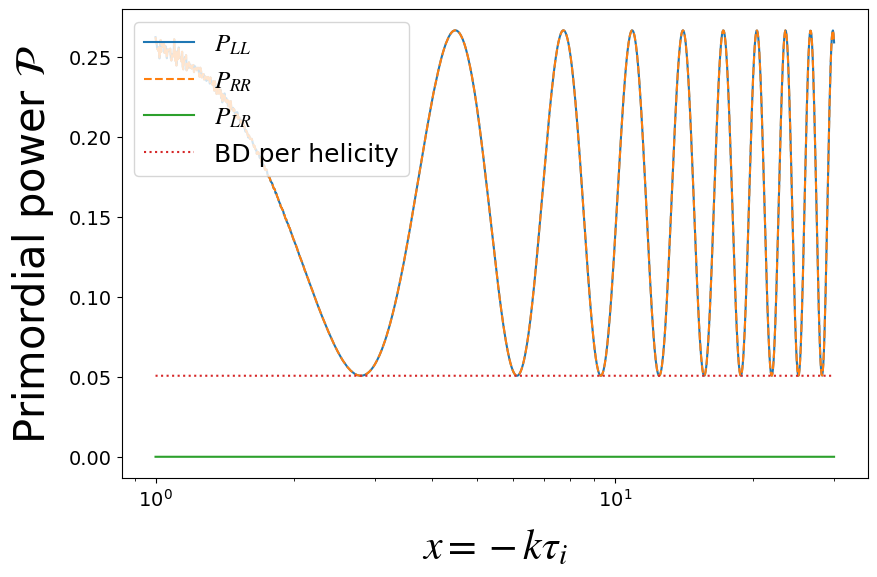

/var/folders/n1/659ydq1n1jbf0nrvbpbbfh7c0000gn/T/ipykernel_1944/1344082849.py:661: ComplexWarning: Casting complex values to real discards the imaginary part
  PLR_time[j] = obs["P_LR"]
/var/folders/n1/659ydq1n1jbf0nrvbpbbfh7c0000gn/T/ipykernel_1944/1344082849.py:662: ComplexWarning: Casting complex values to real discards the imaginary part
  rho_time[j] = obs["rho_LR"]


Finished.
lambda_g = 1633.1270903906156
theta_g = -2.468971239333275
minimum normalizability eigenvalue over final k-grid = 5.118543e-02
max |rho_(LR)| over final k-grid = 9.000000e-01
initial W =  -0.9999999999999999j
final W =  -0.48008185191780567j
initial Im(W) =  -0.9999999999999999
final Im(W) =  -0.48008185191780567
max |Re(W)| =  0.0
J_final range = [2.17946297e-01, 4.99999897e-01]
max |J_final - 1/2| = 2.82053703e-01

Outputs:
  GR_LR_BD_outputs/case_B/GR_LR_power_spectra.csv
  tensor_chirality.png
  run_settings.json
  tensor_power_spectra.png
  tensor_power_ratio.png
  tensor_cross_correlation.png
  tensor_total_power_ratio.png
  tensor_time_evolution.png
Pi range = [-0.000000e+00, -0.000000e+00]


In [ ]:

BTILDE1_AMP = 0.00
BTILDE1_PHASE = 0.0

BTILDE2_AMP = 0.45
BTILDE2_PHASE = 0.0
OUTPUT_DIR = Path("GR_LR_BD_outputs") / "case_B"

results_B = main()

## Case C: $\widetilde b_1=\widetilde b_2=0.30$ (new L/R state)

This case need not have equal L/R power, even though the dynamics are GR.

Running tensor (L, R) entanglement (new LR state, b2=0) calculation
tau0 = -1.000000e+00
tauf = -3.333333e-05
btilde1 = (0.3+0j)
btilde2 = (0.3+0j)



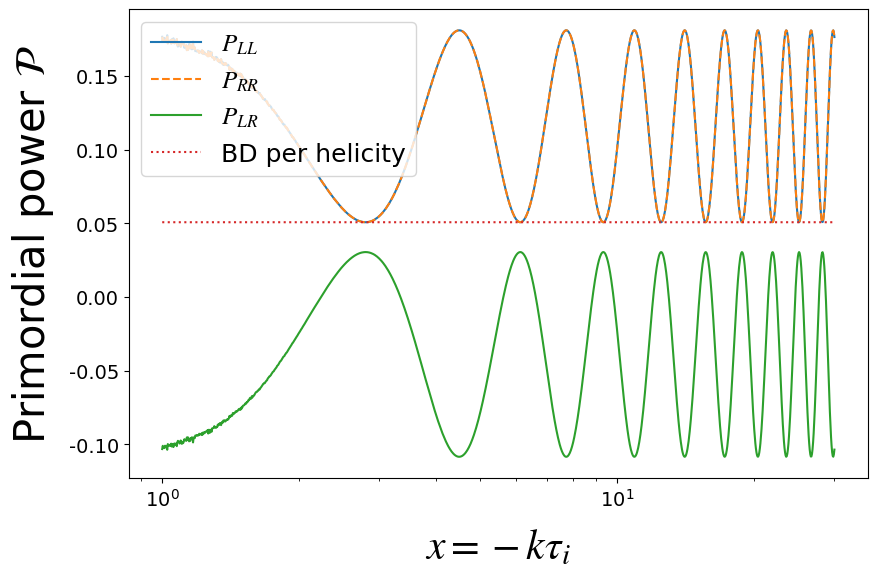

/var/folders/n1/659ydq1n1jbf0nrvbpbbfh7c0000gn/T/ipykernel_1944/1344082849.py:661: ComplexWarning: Casting complex values to real discards the imaginary part
  PLR_time[j] = obs["P_LR"]
/var/folders/n1/659ydq1n1jbf0nrvbpbbfh7c0000gn/T/ipykernel_1944/1344082849.py:662: ComplexWarning: Casting complex values to real discards the imaginary part
  rho_time[j] = obs["rho_LR"]


Finished.
lambda_g = 1623.4549135232987
theta_g = -2.438997006311261
minimum normalizability eigenvalue over final k-grid = 7.850766e-02
max |rho_(LR)| over final k-grid = 8.485281e-01
initial W =  -0.9999999999999999j
final W =  -0.5473095562139172j
initial Im(W) =  -0.9999999999999999
final Im(W) =  -0.5473095562139172
max |Re(W)| =  0.0
J_final range = [2.64516384e-01, 4.99999908e-01]
max |J_final - 1/2| = 2.35483616e-01

Outputs:
  GR_LR_BD_outputs/case_C/GR_LR_power_spectra.csv
  tensor_chirality.png
  run_settings.json
  tensor_power_spectra.png
  tensor_power_ratio.png
  tensor_cross_correlation.png
  tensor_total_power_ratio.png
  tensor_time_evolution.png
Pi range = [-0.000000e+00, -0.000000e+00]


In [ ]:
BTILDE1_AMP = 0.30
BTILDE1_PHASE = 0.0

BTILDE2_AMP = 0.30
BTILDE2_PHASE = 0.0
OUTPUT_DIR = Path("GR_LR_BD_outputs") / "case_C"

results_C = main()

## Total-power comparison (original normalization retained)

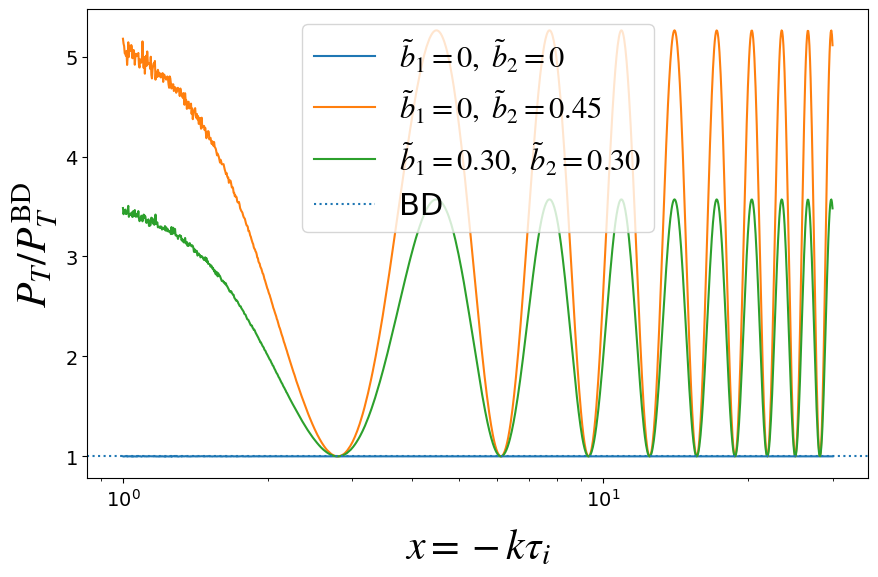

In [ ]:
plt.figure(figsize=STYLE["figure_size"])
plt.semilogx(
    results_A["x_initial"],
    results_A["P_total_ratio"],
    label=r"$\tilde b_1=0,\ \tilde b_2=0$"
)
plt.semilogx(
    results_B["x_initial"],
    results_B["P_total_ratio"],
    label=r"$\tilde b_1=0,\ \tilde b_2=0.45$"
)
plt.semilogx(
    results_C["x_initial"],
    results_C["P_total_ratio"],
    label=r"$\tilde b_1=0.30,\ \tilde b_2=0.30$"
)
plt.axhline(1.0, linestyle=":", label="BD")
plt.xlabel(r"$x=-k\tau_i$", labelpad=11)
plt.ylabel(r"$P_T/P_T^{\rm BD}$")
plt.legend()
plt.tight_layout()
comparison_dir = Path("GR_LR_BD_outputs")
plt.savefig(comparison_dir / "Total_power_ratio_comparison.png", dpi=220)
plt.show()

plt.close()


## Chirality comparison: initial-state asymmetry vs GR dynamics

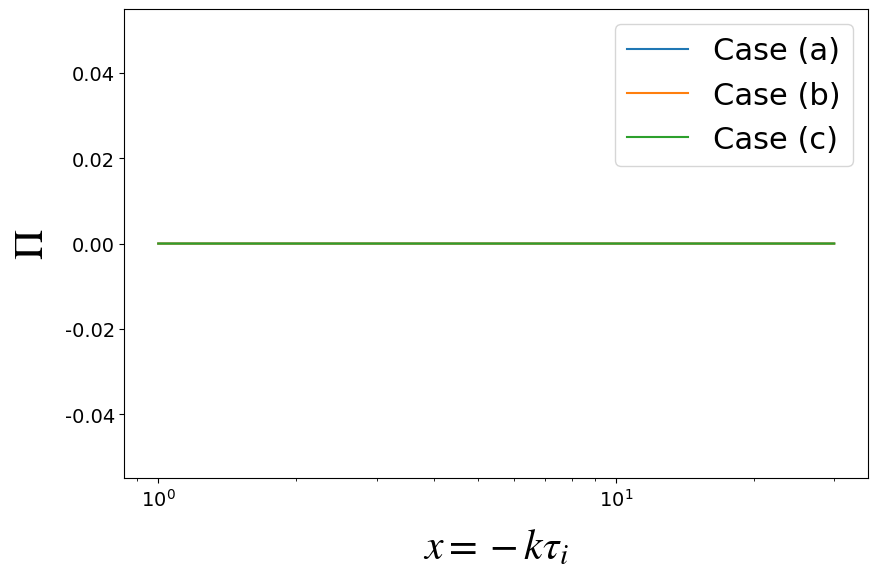

In [ ]:
# A and B have b3=0, hence Pi=0 (up to numerical roundoff).
# C has a different initial state with b3!=0 and can have nonzero Pi in GR.
plt.figure(figsize=STYLE["figure_size"])
for name, result in [("(a)", results_A), ("(b)", results_B), ("(c)", results_C)]:
    plt.semilogx(result["x_initial"], result["Pi"], label=f"Case {name}")
plt.xlabel(r"$x=-k\tau_i$", labelpad=11)
plt.ylabel(r"$\Pi$", labelpad=9)
plt.legend()
plt.tight_layout()
plt.savefig(Path("GR_LR_BD_outputs") / "Pi_comparison.png", dpi=220)
plt.show()
plt.close()


$(\tilde{b}_1,\tilde{b}_2)=(0,\,0.45)$: data shape = (1200, 17)
$(\tilde{b}_1,\tilde{b}_2)=(0,\,0.45)$: max |Pi| = 0.000e+00
$(\tilde{b}_1,\tilde{b}_2)=(0,\,0.45)$: max p_lin = 0.900000
$(\tilde{b}_1,\tilde{b}_2)=(0.30,\,0.30)$: data shape = (1200, 17)
$(\tilde{b}_1,\tilde{b}_2)=(0.30,\,0.30)$: max |Pi| = 0.000e+00
$(\tilde{b}_1,\tilde{b}_2)=(0.30,\,0.30)$: max p_lin = 0.848528


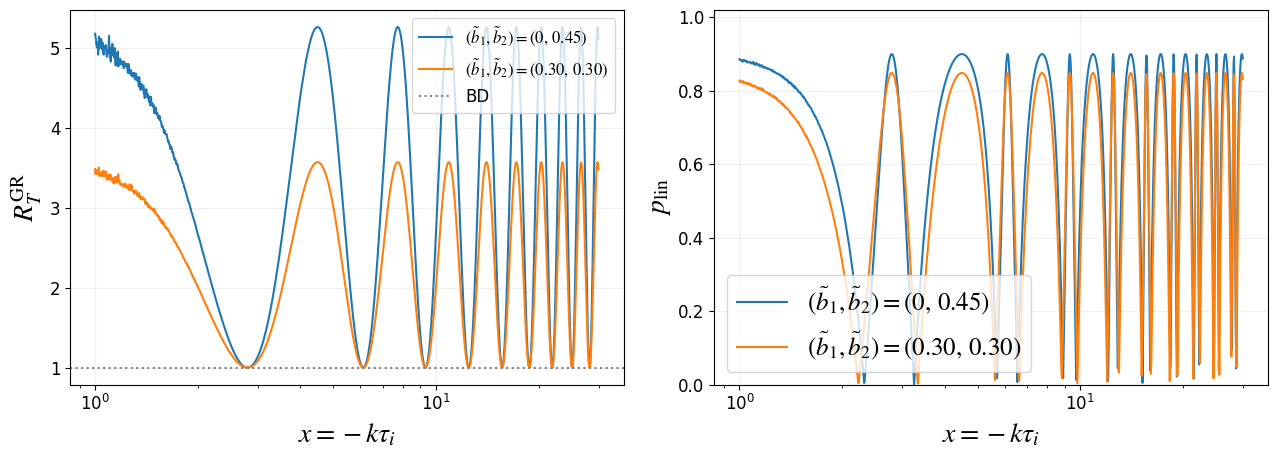

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

root = Path("GR_LR_BD_outputs")

# Case A は除外
cases = {
    r"$(\tilde{b}_1,\tilde{b}_2)=(0,\,0.45)$": "case_B",
    r"$(\tilde{b}_1,\tilde{b}_2)=(0.30,\,0.30)$": "case_C"
}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

for label, folder in cases.items():

    file = root / folder / "GR_LR_power_spectra.csv"

    # 元の17列の複素数CSVを読み込む
    data = np.loadtxt(
        file,
        delimiter=",",
        skiprows=1,
        dtype=complex,
        ndmin=2
    )

    print(f"{label}: data shape = {data.shape}")

    if data.shape[1] != 17:
        raise ValueError("CSVの列数が17ではありません。")

    x = data[:, 1].real
    PL = data[:, 3].real
    PR = data[:, 4].real
    PLR = data[:, 5]
    PBD_total = data[:, 9].real

    # (a) Total tensor power ratio
    R_T = (PL + PR) / PBD_total

    # (b) Linear-polarization degree
    p_lin = 2 * np.abs(PLR) / (PL + PR)

    # GRでPi=0になっているか確認
    Pi = (PL - PR) / (PL + PR)

    print(f"{label}: max |Pi| = {np.max(np.abs(Pi)):.3e}")
    print(f"{label}: max p_lin = {np.max(p_lin):.6f}")

    if np.max(np.abs(Pi)) > 1e-6:
        raise ValueError("Pi != 0: b3の初期条件を確認")

    idx = np.argsort(x)

    axes[0].plot(x[idx], R_T[idx], label=label)
    axes[1].plot(x[idx], p_lin[idx], label=label)

# BD reference
axes[0].axhline(
    1, color="gray", linestyle=":", label="BD"
)

axes[0].set_ylabel(r"$R_T^{\rm GR}$", fontsize=20)
axes[0].legend(fontsize=12)

axes[1].set_ylabel(r"$p_{\rm lin}$", fontsize=20)
axes[1].set_ylim(0, 1.02)
axes[1].legend(loc="lower left", fontsize=18)

for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel(r"$x=-k\tau_i$", fontsize=20)
    ax.tick_params(labelsize=12)
    ax.grid(alpha=0.2)

fig.tight_layout()

output = root / "paper_figures"
output.mkdir(parents=True, exist_ok=True)

fig.savefig(output / "GR_Rt_plin_BC.pdf",
            bbox_inches="tight")
fig.savefig(output / "GR_Rt_plin_BC.png",
            dpi=300, bbox_inches="tight")

plt.show()
